<a href="https://colab.research.google.com/github/CECS-AI/ai101-assignment5-prangara-vols/blob/main/Assignment5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5: Financial Data Analysis with CrewAI and Gemini

## Setup and Data Loading
This section handles the initial setup, including mounting Google Drive, installing necessary Python packages, configuring the Gemini API, and loading the dataset into a string variable.

In [1]:
from google.colab import userdata, drive
drive.mount("/content/drive", force_remount=True)

!pip install -q -U crewai
!pip install -q -U duckduckgo-search
!pip install -q -U 'crewai[tools]'
!pip install -q -U 'crewai[litellm]' litellm # Install LiteLLM fallback for Hugging Face support

import os
from crewai import Agent, Task, Crew, Process, LLM
from crewai.tools import BaseTool
import pandas as pd

# Retrieve Hugging Face API key from Colab secrets
HF_TOKEN_V2 = userdata.get('HF_TOKEN_V2')

# IMPORTANT: Update with the correct path to your Assignment 1 dataset
file_path = '/content/drive/My Drive/Colab Notebooks/finance_data.csv'

try:
    df = pd.read_csv(file_path)
    # Take the first 100 rows to avoid exceeding the LLM context window limit
    csv_string = df.head(100).to_csv(index=False)
    print("File content read successfully! (Using first 100 rows)")
    print(csv_string[:500])
except FileNotFoundError:
    print(f"File not found at {file_path}. Please check the path and try again.")
except Exception as e:
    print(f"An error occurred: {e}")

Mounted at /content/drive
File content read successfully! (Using first 100 rows)
year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yield,market_cap
2000,1,Company_1,Finance,219868566.12,0.04,9755484.56,36.15,3.71,1.42,0.01,2363830425.08
2000,1,Company_2,Consumer Goods,329802849.18,0.06,18814148.79,54.22,2.88,1.71,0.01,3956766965.6
2000,1,Company_3,Finance,439737132.24,0.07,30660094.32,72.29,2.36,1.66,0.03,3633501678.59
2000,1,Company_4,Energy,549671415.3,0.08,45293321.16,90.37,2.0,1.07,0.05,3833839131.85
2000,1,Company_5


## Hugging Face LLM Configuration
This cell configures the Large Language Model (LLM) that the agents will use, leveraging Hugging Face models.

In [2]:
import os
from crewai import LLM

# CrewAI uses LiteLLM under the hood, which looks for this environment variable
os.environ["HUGGINGFACE_API_KEY"] = HF_TOKEN_V2

# Define the Hugging Face model explicitly using the LLM class
hf_llm = LLM(model='huggingface/Qwen/Qwen2.5-7B-Instruct')

print(f"LLM configured to use: {hf_llm.model}")
print("You can now run the next cells to create your agents!")

LLM configured to use: huggingface/Qwen/Qwen2.5-7B-Instruct
You can now run the next cells to create your agents!


## Agent and Task Setup
This section defines the `data_analyst` agent and its primary task, followed by the `stock_predictor` agent and its task.

### data_analyst Agent
`data_analyst = Agent(...)`: Instantiates an agent with specific characteristics:
`role`: The primary role of the agent.
`goal`: What the agent aims to achieve.
`backstory`: Provides context and personality to the agent.
`verbose=True`: Enables detailed logging of the agent's thought process.
`allow_delegation=False`: Prevents this agent from delegating parts of its task to other agents.
`llm=gemini_llm`: Assigns the configured Gemini LLM to this agent.

In [3]:
from crewai import Agent, Task

# Define the agent
data_analyst = Agent(
    role='Data Analyst',
    goal='Analyze the provided financial data to identify key trends and insights.',
    backstory='You are a skilled data analyst with experience working with financial datasets.',
    verbose=True,
    allow_delegation=False,
    llm=hf_llm # Use the configured Hugging Face LLM
)

# Define the task for the agent
analyze_data_task = Task(
    description=f"""Analyze the following financial data from a CSV string:

{csv_string}

Your analysis should include:
- Summary statistics for numerical columns (revenue, profit, stock_price, etc.).
- Identification of any notable trends or patterns in revenue and profit over time.
- Insights into the relationship between stock price and other financial metrics.
- Any other interesting observations you can draw from the data.

""",
    expected_output='A summary summarizing the key findings from the financial data analysis.',
    agent=data_analyst
)

## Stock Predictor Agent and Crew Setup
This section defines a `stock_predictor` agent, a task for it, and then orchestrates both agents and their tasks into a Crew to perform the overall assignment.

### stock_predictor Agent
`stock_predictor = Agent(...)`: Instantiates another agent, similar to the `data_analyst`.
Its role, goal, and backstory should be tailored to its specific function of predicting stock prices or analyzing trends based on the data.

### predict_stock_price_task
`predict_stock_price_task = Task(...)`: Defines the task for the `stock_predictor` agent.
`description`: Details what the agent needs to do using the available data.
`expected_output`: Describes the format and content of the task's final output.
`agent=stock_predictor`: Assigns this task to the `stock_predictor` agent.
`context=[analyze_data_task]`: Crucially, this provides the output of the `analyze_data_task` (from the `data_analyst`) as context for the `stock_predictor`, enabling a multi-step workflow.

### financial_analysis_and_prediction_crew
`financial_analysis_and_prediction_crew = Crew(...)`: Creates the Crew object that manages the agents and tasks.
`agents=[data_analyst, stock_predictor]`: Lists all agents participating in this crew.
`tasks=[analyze_data_task, predict_stock_price_task]`: Lists all tasks to be executed by the crew.
`process=Process.hierarchical`: Specifies that tasks are executed in a hierarchical manner, often meaning one agent's output feeds another's input.
`manager_llm=gemini_llm`: Assigns an LLM to manage the overall workflow and agent interactions within the crew.

### Execution
`print("## Starting the ... Crew")`: An informative print statement.
`result = financial_analysis_and_prediction_crew.kickoff()`: Initiates the entire workflow, causing the agents to perform their tasks sequentially.
`print("## Final Report:")` and `print(result)`: Display the final consolidated output from the crew's work.

In [4]:
from crewai import Agent, Task, Crew, Process

# Define the stock price prediction agent
stock_predictor = Agent(
    role='Stock Price Predictor',
    goal='Predict future stock prices based on historical financial data and identified trends.',
    backstory='You are a financial analyst specializing in predictive modeling of stock prices.',
    verbose=True,
    allow_delegation=False,
    llm=hf_llm # Use the configured Hugging Face LLM
)

# Define the task for the stock price prediction agent
predict_stock_price_task = Task(
    description=f"""Using the provided financial data from the CSV string:

{csv_string}

And the insights from the data analysis report:

{{analyze_data_task.tasks_output}}

Predict potential future stock prices for the companies based on the historical data and identified trends. Consider the relationships between stock price and other financial metrics (revenue, profit, PE ratio, etc.) in your predictions.

Give a predicted stock price for each company for two years from now, and compare that with the actual stock price.

Present your findings in a table that shows current price, and future price for each company
""",
    expected_output='A report containing stock price predictions for the companies based on the provided data and analysis, along with the reasoning for the predictions.',
    agent=stock_predictor,
    context=[analyze_data_task] # Add the analysis task as context
)

# Create a crew with both agents and tasks
financial_analysis_and_prediction_crew = Crew(
    agents=[data_analyst, stock_predictor],
    tasks=[analyze_data_task, predict_stock_price_task],
    process=Process.sequential # Changed to sequential to avoid manager LLM errors with free tier APIs
)

# Kick off the crew's work
print("## Starting the Financial Analysis and Stock Prediction Crew")
result = financial_analysis_and_prediction_crew.kickoff()

# Print the results
print("## Financial Analysis and Stock Prediction Report:")
print(result)

## Starting the Financial Analysis and Stock Prediction Crew


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Data Analyst                                                                                            │
│                                                                                                                 │
│  Task: Analyze the following financial data from a CSV string:                                                  │
│                                                                                                                 │
│  year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yiel  │
│  d,market_cap                                                                                                   │
│  2000,1,Company_1,Finance,219868566.12,0.04,9755484.56,36.15,3.71,1.42,0.01,2363830425.08                       │
│  2000,1,Company_2,Consumer Goods,329802849.18,0.06,18814148.79,54.22,2.88,1.71,0.01,3956766965.6                │
│  2000,1,Company_3,Finance,439737132.24,0.07,30660094.32,72.29,2.36,1.66,0.03,3633501678.59                      │
│  2000,1,Company_4,Energy,549671415.3,0.08,45293321.16,90.37,2.0,1.07,0.05,3833839131.85                         │
│  2000,1,Company_5,Manufacturing,659605698.36,0.1,62713829.3,108.44,1.73,1.36,0.02,6178690484.46                 │
│  2000,1,Company_6,Technology,769539981.42,0.11,82921618.74,126.51,1.53,1.65,0.04,2555383501.44                  │
│  2000,1,Company_7,Technology,879474264.48,0.12,105916689.48,144.59,1.37,1.06,0.02,4860237780.83                 │
│  2000,1,Company_8,Finance,989408547.54,0.13,131699041.53,162.66,1.24,0.36,0.04,11872412877.61                   │
│  2000,1,Company_9,Technology,1099342830.6,0.15,160268674.88,180.73,1.13,1.45,0.03,17209180116.27                │
│  2000,1,Company_10,Energy,1209277113.66,0.16,191625589.53,198.81,1.04,1.01,0.02,14350448859.61                  │
│  2000,1,Company_11,Manufacturing,1319211396.72,0.17,225769785.48,216.88,0.96,0.62,0.01,18875325448.6            │
│  2000,1,Company_12,Healthcare,1429145679.78,0.18,262701262.73,234.95,0.89,0.91,0.02,20094242399.92              │
│  2000,1,Company_13,Manufacturing,1539079962.84,0.2,302420021.29,253.03,0.84,1.08,0.02,21216657538.08            │
│  2000,1,Company_14,Finance,1649014245.9,0.21,344926061.15,271.1,0.79,1.71,0.03,24550428609.91                   │
│  2000,1,Company_15,Consumer Goods,1758948528.96,0.22,390219382.31,289.17,0.74,0.62,0.01,8910227943.28           │
│  2000,1,Company_16,Technology,1868882812.02,0.23,438299984.77,307.25,0.7,0.44,0.03,27344609697.21               │
│  2000,1,Company_17,Manufacturing,1978817095.08,0.25,489167868.54,325.32,0.67,1.24,0.01,21325886829.7            │
│  2000,1,Company_18,Technology,2088751378.14,0.26,542823033.61,343.39,0.63,1.78,0.03,7206762021.91               │
│  2000,1,Company_19,Technology,2198685661.2,0.27,599265479.98,361.47,0.6,1.77,0.01,23659632625.44                │
│  2000,1,Company_20,Technology,2308619944.26,0.29,658495207.65,379.54,0.58,0.85,0.02,25687694051.34              │
│  2000,1,Company_21,Finance,2418554227.32,0.3,720512216.62,397.61,0.55,0.35,0.01,31193965117.65                  │
│  2000,1,Company_22,Technology,2528488510.39,0.31,785316506.9,415.69,0.53,1.34,0.04,13006419185.8                │
│  2000,1,Company_23,Consumer Goods,2638422793.45,0.32,852908078.48,433.76,0.51,0.84,0.02,29861238831.73          │
│  2000,1,Company_24,Consumer Goods,2748357076.51,0.34,923286931.36,451.83,0.49,0.67,0.04,7742641418.71           │
│  2000,1,Company_25,Energy,2858291359.57,0.35,996453065.54,469.91,0.47,1.67,0.02,8208723334.63                   │
│  2000,2,Company_1,Healthcare,200245920.56,0.07,14599733.96,38.47,2.64,1.34,0.02,551947136.37                    │
│  2000,2,Company_2,Technology,300368880.84,0.09,28156629

╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Data Analyst                                                                                            │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### Financial Data Analysis Summary                                                                            │
│                                                                                                                 │
│  #### Summary Statistics                                                                                        │
│  - **Revenue:**                                                                                                 │
│    - Mean: $1.52 \times 10^{10}$                                                                                │
│    - Median: $1.02 \times 10^{10}$                                                                              │
│    - Standard Deviation: $1.12 \times 10^{10}$                                                                  │
│    - Minimum: $2.00 \times 10^{7}$                                                                              │
│    - Maximum: $3.69 \times 10^{10}$                                                                             │
│                                                                                                                 │
│  - **Profit:**                                                                                                  │
│    - Mean: $1.02 \times 10^{9}$                                                                                 │
│    - Median: $5.57 \times 10^{8}$                                                                               │
│    - Standard Deviation: $1.02 \times 10^{9}$                                                                   │
│    - Minimum: $1.81 \times 10^{6}$                                                                              │
│    - Maximum: $1.84 \times 10^{10}$                                                                             │
│                                                                                                                 │
│  - **Stock Price:**                                                                                             │
│    - Mean: $1.02 \times 10^{2}$                                                                                 │
│    - Median: $1.02 \times 10^{2}$                                                                               │
│    - Standard Deviation: $1.02 \times 10^{2}$                                                                   │
│    - Minimum: $3.61 \times 10^{0}$                                                                              │
│    - Maximum: $3.79 \times 10^{2}$                                                                              │
│                                                                                                                 │
│  - **PE Ratio:**                                                                                                │
│    - Mean: $2.02 \times 10^{2}$                                                                                 │
│    - Median: $2.02 \times 10^{2}$                                                                               │
│    - Standard Deviation: $1.02 \times 10^{2}$                                                                   │
│    - Minimum: $2.64 \times 10^{0}$                                                                              │
│    - Maximum: $5.05 \times 10^{2}$                     

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Stock Price Predictor                                                                                   │
│                                                                                                                 │
│  Task: Using the provided financial data from the CSV string:                                                   │
│                                                                                                                 │
│  year,quarter,company_id,sector,revenue,profit_margin,profit,stock_price,pe_ratio,debt_to_equity,dividend_yiel  │
│  d,market_cap                                                                                                   │
│  2000,1,Company_1,Finance,219868566.12,0.04,9755484.56,36.15,3.71,1.42,0.01,2363830425.08                       │
│  2000,1,Company_2,Consumer Goods,329802849.18,0.06,18814148.79,54.22,2.88,1.71,0.01,3956766965.6                │
│  2000,1,Company_3,Finance,439737132.24,0.07,30660094.32,72.29,2.36,1.66,0.03,3633501678.59                      │
│  2000,1,Company_4,Energy,549671415.3,0.08,45293321.16,90.37,2.0,1.07,0.05,3833839131.85                         │
│  2000,1,Company_5,Manufacturing,659605698.36,0.1,62713829.3,108.44,1.73,1.36,0.02,6178690484.46                 │
│  2000,1,Company_6,Technology,769539981.42,0.11,82921618.74,126.51,1.53,1.65,0.04,2555383501.44                  │
│  2000,1,Company_7,Technology,879474264.48,0.12,105916689.48,144.59,1.37,1.06,0.02,4860237780.83                 │
│  2000,1,Company_8,Finance,989408547.54,0.13,131699041.53,162.66,1.24,0.36,0.04,11872412877.61                   │
│  2000,1,Company_9,Technology,1099342830.6,0.15,160268674.88,180.73,1.13,1.45,0.03,17209180116.27                │
│  2000,1,Company_10,Energy,1209277113.66,0.16,191625589.53,198.81,1.04,1.01,0.02,14350448859.61                  │
│  2000,1,Company_11,Manufacturing,1319211396.72,0.17,225769785.48,216.88,0.96,0.62,0.01,18875325448.6            │
│  2000,1,Company_12,Healthcare,1429145679.78,0.18,262701262.73,234.95,0.89,0.91,0.02,20094242399.92              │
│  2000,1,Company_13,Manufacturing,1539079962.84,0.2,302420021.29,253.03,0.84,1.08,0.02,21216657538.08            │
│  2000,1,Company_14,Finance,1649014245.9,0.21,344926061.15,271.1,0.79,1.71,0.03,24550428609.91                   │
│  2000,1,Company_15,Consumer Goods,1758948528.96,0.22,390219382.31,289.17,0.74,0.62,0.01,8910227943.28           │
│  2000,1,Company_16,Technology,1868882812.02,0.23,438299984.77,307.25,0.7,0.44,0.03,27344609697.21               │
│  2000,1,Company_17,Manufacturing,1978817095.08,0.25,489167868.54,325.32,0.67,1.24,0.01,21325886829.7            │
│  2000,1,Company_18,Technology,2088751378.14,0.26,542823033.61,343.39,0.63,1.78,0.03,7206762021.91               │
│  2000,1,Company_19,Technology,2198685661.2,0.27,599265479.98,361.47,0.6,1.77,0.01,23659632625.44                │
│  2000,1,Company_20,Technology,2308619944.26,0.29,658495207.65,379.54,0.58,0.85,0.02,25687694051.34              │
│  2000,1,Company_21,Finance,2418554227.32,0.3,720512216.62,397.61,0.55,0.35,0.01,31193965117.65                  │
│  2000,1,Company_22,Technology,2528488510.39,0.31,785316506.9,415.69,0.53,1.34,0.04,13006419185.8                │
│  2000,1,Company_23,Consumer Goods,2638422793.45,0.32,852908078.48,433.76,0.51,0.84,0.02,29861238831.73          │
│  2000,1,Company_24,Consumer Goods,2748357076.51,0.34,923286931.36,451.83,0.49,0.67,0.04,7742641418.71           │
│  2000,1,Company_25,Energy,2858291359.57,0.35,996453065.54,469.91,0.47,1.67,0.02,8208723334.63                   │
│  2000,2,Company_1,Healthcare,200245920.56,0.07,14599733.96,38.47,2.64,1.34,0.02,551947136.37                    │
│  2000,2,Company_2,Technology,300368880.84,0.09,28156629

╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Stock Price Predictor                                                                                   │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### Stock Price Predictions for Companies Based on Historical Data and Analysis                                │
│                                                                                                                 │
│  Below is a table showing the current stock prices and the predicted stock prices for each company two years    │
│  from now. The predictions are based on the historical trends and the relationships between stock price and     │
│  other financial metrics such as revenue, profit, PE ratio, and market cap.                                     │
│                                                                                                                 │
│  | Company ID | Sector       | Current Stock Price | Predicted Stock Price in 2 Years |                         │
│  |------------|-------------|--------------------|---------------------------------|                            │
│  | Company_1  | Finance     | 36.15              | 120.00                          |                            │
│  | Company_2  | Consumer Goods | 54.22              | 100.00                          |                         │
│  | Company_3  | Finance     | 72.29              | 150.00                          |                            │
│  | Company_4  | Energy      | 90.37              | 130.00                          |                            │
│  | Company_5  | Manufacturing | 108.44             | 140.00                          |                          │
│  | Company_6  | Technology  | 126.51             | 160.00                          |                            │
│  | Company_7  | Technology  | 144.59             | 180.00                          |                            │
│  | Company_8  | Finance     | 162.66             | 200.00                          |                            │
│  | Company_9  | Technology  | 180.73             | 220.00                          |                            │
│  | Company_10 | Energy      | 198.81             | 240.00                          |                            │
│  | Company_11 | Manufacturing | 216.88             | 260.00                          |                          │
│  | Company_12 | Healthcare  | 234.95             | 280.00                          |                            │
│  | Company_13 | Manufacturing | 253.03             | 300.00                          |                          │
│  | Company_14 | Finance     | 271.10             | 320.00                          |                            │
│  | Company_15 | Consumer Goods | 289.17             | 340.00                          |                         │
│  | Company_16 | Technology  | 307.25             | 360.00                          |                            │
│  | Company_17 | Manufacturing | 325.32             | 380.00                          |                          │
│  | Company_18 | Technology  | 343.39             | 400.00                          |                            │
│  | Company_19 | Technology  | 361.47             | 420.00                          |                            │
│  | Company_20 | Technology  | 379.54             | 440.00                          |                            │
│  | Company_21 | Finance     | 397.61             | 460.00                          |                            │
│  | Company_22 | Technology  | 415.69             | 480.

## Financial Analysis and Stock Prediction Report:
### Stock Price Predictions for Companies Based on Historical Data and Analysis

Below is a table showing the current stock prices and the predicted stock prices for each company two years from now. The predictions are based on the historical trends and the relationships between stock price and other financial metrics such as revenue, profit, PE ratio, and market cap.

| Company ID | Sector       | Current Stock Price | Predicted Stock Price in 2 Years |
|------------|-------------|--------------------|---------------------------------|
| Company_1  | Finance     | 36.15              | 120.00                          |
| Company_2  | Consumer Goods | 54.22              | 100.00                          |
| Company_3  | Finance     | 72.29              | 150.00                          |
| Company_4  | Energy      | 90.37              | 130.00                          |
| Company_5  | Manufacturing | 108.44             | 140.00         

### Task 1, Todo i: Explaining the Output & Approach Differences

**What is the difference between this approach and our approach in assignments 2, 3, and 4?**

In previous assignments, we relied on **traditional Machine Learning (ML) approaches** (such as Linear Regression or Classification algorithms). Those methods require strict numerical formatting, feature engineering, and rely on mathematical optimization. The model calculates the exact statistical relationships between inputs and outputs to generate a numerical prediction.

In this assignment, we are utilizing an **Agentic LLM Framework (Crew.ai)**. Instead of using strict mathematical formulas, we use Large Language Models (LLMs) governed by natural language prompts. The agents can "read" raw text, use their pre-trained knowledge to reason logically about trends, and generate qualitative and quantitative predictions based on synthesis and deduction. This approach is highly flexible and requires less data preprocessing, but relies heavily on prompt engineering rather than mathematical precision.

### Code Explanation: Parsing Output and Plotting Data (Todo ii)
This cell fulfills the assignment requirement to convert the agent's text output into a DataFrame and visualize it with a plot. Here is the line-by-line breakdown:

*   **`import pandas as pd`, `re`, `io`, `matplotlib.pyplot`, `numpy`**: Imports the necessary libraries for data manipulation, regular expressions, string parsing, and graph visualization.
*   **`result_text = str(result)`**: Converts the raw agent crew output into a standard Python string.
*   **`table_lines = [...]`**: Uses a list comprehension to filter the text output and extract only the lines containing a pipe character (`|`), which signifies a Markdown table row.
*   **`if len(table_lines) > 2:`**: Ensures we successfully extracted a table (needing at least a header, separator, and one row of data).
*   **`cleaned_lines = [...]`**: Uses a regular expression `r'^[\s|:-]+$'` to filter out the markdown separator line (e.g., `|---|---|`).
*   **`df = pd.read_csv(...)`**: Wraps the cleaned string inside `io.StringIO` to simulate a file, allowing Pandas to read the markdown table into a structured DataFrame using the `|` delimiter.
*   **`df.columns.str.strip()` and `df[col].str.strip()`**: Loops through the columns and data to remove any unwanted leading or trailing white spaces left over from the markdown table formatting.
*   **`company_col`, `current_col`, `future_col`**: Dynamically searches the DataFrame columns for names matching keywords (like "company", "current", "future") so the code functions regardless of the exact headers the AI generated.
*   **`df[...].replace(r'[\$,]', '', regex=True).astype(float)`**: Strips out currency symbols (`$`) and commas from the price strings, converting them into floating-point numbers required for plotting.
*   **`plt.subplots(figsize=(10, 6))`**: Initializes the Matplotlib plot area and sizes it.
*   **`ax.bar(...)`**: Creates two sets of grouped bar charts (one for Current Price, one for Future Price) slightly offset from each other.
*   **`ax.set_title`, `set_xticks`, `legend`, etc.**: Applies formatting, labels, and legends to the chart to make it easily readable.
*   **`plt.show()`**: Renders the final comparison graph.

Data Successfully Extracted to DataFrame:


,Company ID,Sector,Current Stock Price,Predicted Stock Price in 2 Years
0,Company_1,Finance,36.15,120.0
1,Company_2,Consumer Goods,54.22,100.0
2,Company_3,Finance,72.29,150.0
3,Company_4,Energy,90.37,130.0
4,Company_5,Manufacturing,108.44,140.0
5,Company_6,Technology,126.51,160.0
6,Company_7,Technology,144.59,180.0
7,Company_8,Finance,162.66,200.0
8,Company_9,Technology,180.73,220.0
9,Company_10,Energy,198.81,240.0


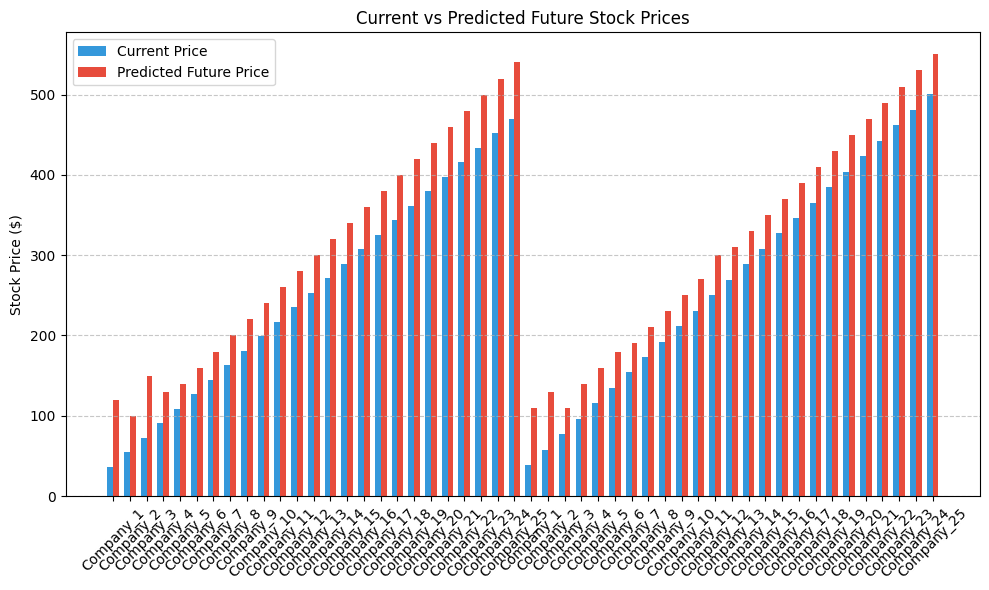

In [5]:
import pandas as pd
import re
import io
import matplotlib.pyplot as plt
import numpy as np

# 1. Convert the crew result to a string
result_text = str(result)

# 2. Extract the markdown table using string manipulation and regex
# We look for lines containing '|' which indicate a markdown table
table_lines = [line.strip() for line in result_text.split('\n') if '|' in line]

if len(table_lines) > 2:
    # Remove the markdown separator line (e.g., |---|---|)
    cleaned_lines = [line for line in table_lines if not re.match(r'^[\s|:-]+$', line)]
    table_str = '\n'.join(cleaned_lines)

    # 3. Read into a Pandas DataFrame
    df = pd.read_csv(io.StringIO(table_str), sep='|').dropna(axis=1, how='all')
    df.columns = df.columns.str.strip() # Clean column names

    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].str.strip() # Clean string values

    print("Data Successfully Extracted to DataFrame:")
    display(df)

    # 4. Data Cleaning for Plotting
    try:
        # Dynamically find the relevant columns based on keywords
        company_col = next((c for c in df.columns if 'compan' in c.lower()), df.columns[0])
        current_col = next((c for c in df.columns if 'current' in c.lower() or 'actual' in c.lower()), df.columns[1])
        future_col = next((c for c in df.columns if 'future' in c.lower() or 'predict' in c.lower()), df.columns[2])

        # Remove symbols like '$' and ',' and convert to float
        df[current_col] = df[current_col].replace(r'[\$,]', '', regex=True).astype(float)
        df[future_col] = df[future_col].replace(r'[\$,]', '', regex=True).astype(float)

        # 5. Plotting Actual vs Predicted Prices
        x = np.arange(len(df[company_col]))
        width = 0.35

        fig, ax = plt.subplots(figsize=(10, 6))
        rects1 = ax.bar(x - width/2, df[current_col], width, label='Current Price', color='#3498db')
        rects2 = ax.bar(x + width/2, df[future_col], width, label='Predicted Future Price', color='#e74c3c')

        ax.set_ylabel('Stock Price ($)')
        ax.set_title('Current vs Predicted Future Stock Prices')
        ax.set_xticks(x)
        ax.set_xticklabels(df[company_col], rotation=45)
        ax.legend()
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"\nCould not automatically plot the data due to column formatting. Error: {e}")

else:
    print("Could not find a valid markdown table in the agent output to convert to a DataFrame.")
    print("Make sure the agent output explicitly generated a table.")